In [2]:
import numpy as np
import pandas as pd

### Question 1

#### Exercise 1.1 (Maximum of two dice). (8 points)


Take two independent fair dice $D \leftarrow \{1,2,3,4,5,6\}$ and consider the larger outcome
$M := max(D_0,D_1)$


(i) Compute $\Pr(M \le a)$ for $a ∈ N≤6$.

### Reasoning
We have two independent fair dice:
$$
D_0, D_1 \in \{1,2,3,4,5,6\}
$$

Define the random variable:
$$
M = \max(D_0, D_1)
$$

The event $M \le a$ means that **both dice outcomes are at most $a$**:
$$
\{M \le a\} = \{D_0 \le a \ \text{and} \ D_1 \le a\}
$$

Since $D_0$ and $D_1$ are independent:
$$
\Pr(M \le a) = \Pr(D_0 \le a)\cdot \Pr(D_1 \le a)
$$

For a fair die:
$$
\Pr(D \le a) = \frac{a}{6}
$$

Therefore:
$$
\Pr(M \le a) = \left(\frac{a}{6}\right)^2 = \frac{a^2}{36}, \quad \text{for } a = 1,2,3,4,5,6
$$


In [3]:
# Evaluating probabilities for each possible instance of a
a_val = np.arange(1, 7)  # stores all possible values of a(1 - 6)

# Calculate Pr(M <= a) for all a using derived formula
pr_m_less_a = (a_val / 6 ) ** 2

# Print results in {a_value: probability} pairs
print("P(M ≤ a):", {int(a): round(float(p), 4) for a, p in zip(a_val, pr_m_less_a)})

P(M ≤ a): {1: 0.0278, 2: 0.1111, 3: 0.25, 4: 0.4444, 5: 0.6944, 6: 1.0}


In [4]:
# Testing out using N random die rolls for  N = 100,000
N = 100_000
d0 = np.random.randint(1, 7, size=N)
d1 = np.random.randint(1, 7, size=N)

M = np.maximum(d0, d1)

for a in range(1, 7):
    prob = (M <= a).mean()
    print(a, prob)

1 0.02818
2 0.11061
3 0.24929
4 0.44513
5 0.69677
6 1.0


(ii) Compute $\Pr(M = a)$ for $a ∈ N≤6$.

### Reasoning
Using the Difference of the Cumulative Distribution Function(CDF) to evaluate PMF (Probability Mass Function). The relationship is defined as:

$$
\Pr(M = a) = \Pr(M \le a) - \Pr(M \le a - 1)
$$

We already know that $\Pr(M \le a) = (a/6)^2 $ hence by subsitution we evaluate

$$
\Pr(M = a) = a^2/36 -  (a- 1)^2/36
$$

i.e $$ \Pr(M = a) = \frac{a^2-(a- 1)^2}{36} $$

Simplify further: $$ = \frac{a^2-(a^2 - 2a + 1)}{36} $$

Final formula = $$ \Pr(M = a) = \frac{2a-1}{36} $$


In [5]:
# Evaluating probabilities for each possible instance of a
a_val = np.arange(1, 7)  # stores all possible values of a(1 - 6)

# Calculate Pr(M = a) for all a using derived formula
pr_m_eq_a = ((2*a_val) - 1)/36 

# Print results in {a_value: probability} pairs
print("P(M = a):", {int(a): round(float(p), 4) for a, p in zip(a_val, pr_m_eq_a)})

P(M = a): {1: 0.0278, 2: 0.0833, 3: 0.1389, 4: 0.1944, 5: 0.25, 6: 0.3056}


In [6]:
# Testing out using random die rolls for  N = 100,000
N = 100_000
d0 = np.random.randint(1, 7, size=N)
d1 = np.random.randint(1, 7, size=N)

M = np.maximum(d0, d1)

for a in range(1, 7):
    prob = (M == a).mean()
    print(a, prob)

1 0.02773
2 0.08248
3 0.13923
4 0.19337
5 0.24832
6 0.30887


(iii) Compute $E[M]$

Since we are dealing with die rolls, we are dealing with discrete variables, hence:

$$
E[M] = \sum_{a=1}^{6} a \cdot \Pr(M = a)
$$

Given previous calculation:
$$ \Pr(M = a) = \frac{2a-1}{36} $$

Substitute:

$$ E[M] = \sum_{a=1}^{6} a \cdot \frac{2a - 1}{36} $$

i.e $$ E[M] = (1(\frac{2*1 - 1}{36})) + (2(\frac{2*2 - 1}{36})) + ... + (6(\frac{2*6 - 1}{36})) $$

In [7]:
# Using Evaluated formula above . Compute for E|M|
# PMF = Pr(M=a) = pr_m_eq_a

a_values = np.arange(1,7)
expectation_val_m = np.sum(a_values * pr_m_eq_a)
print(f" E|M| = {expectation_val_m:.4f}")

 E|M| = 4.4722


(iv) Compute $ E[M^2] $ and derive $ var[M] $.

To evaluate for $E[M^2]$ the formula below is used:

$$
E[M^2] = \sum_{a=1}^{6} a^2 \cdot \Pr(M = a)
$$

Therefore substituting the knowns:

$$ E[M^2] = \sum_{a=1}^{6} a^2 \cdot \frac{2a-1}{36}$$

i.e $$ E[M^2] = (1(\frac{2*1 - 1}{36})) + (4(\frac{2*2 - 1}{36})) + ... + (36(\frac{2*6 - 1}{36})) $$


In [8]:
# First square the a values (1 - 6)
a_val_sq = np.square(a_values)

# Calculate E[M^2]
E_squared = np.sum(a_val_sq * pr_m_eq_a)
print(f" E[M^2] = {E_squared:.4f}")


 E[M^2] = 21.9722


Having obtained our $ E[M^2] $ and knowing our E[M] value we use the formula below to calculate variance 

$$ \mathrm{Var}(M) = E[M^2] - (E[M])^2 $$

$$E[M^2] = 21.9722$$
$$E[M] = 4.4722$$

Hence, $Var(M)$:

$$ Var(M) = 21.9722 - (4.4722)^2 $$

In [9]:
# Calculating Var(M)

variance_m = (E_squared - (expectation_val_m**2))
print(f" Var(M) = {variance_m:.4f}")

 Var(M) = 1.9715


#### Exercise 1.2 (Maximum of two dice). (8 points)


Apply Markov’s and Chebyshev’s inequalities). (12 points)


In this exercise you shall test the quality of Markov’s and Chebyshev’s inequalities.

(i) Consider a uniform real number from the unit interval, i.e. $U ← [0, 1]$ uniformly chosen.


(a) Plot $ prob(U ≥ a) $ and $ \frac{EU}{a} $ as functions of a

Uniform distribution, U = (0,1), means that values are evenly spread between 0 & 1 

In [10]:
import matplotlib.pyplot as plt

np.random.seed(42)

# No of iterations to run
N = 300_000
uniform_dist = np.random.uniform(0, 1, N)

# Evaluate Monte Carlo Estimates
expectation_u = np.mean(uniform_dist)
variance_u = np.var(uniform_dist)

print(f"E[U] = {expectation_u:.4f}")
print(f"Var[U] = {variance_u:.4f}")

E[U] = 0.5005
Var[U] = 0.0833


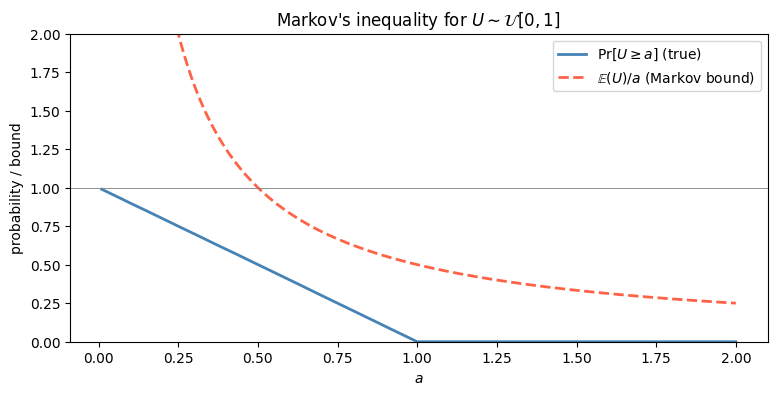

In [11]:
# Plotting True Probability Distribution vs Markov's Inequality Bound

# Store all possible values of variable a
a_values = np.linspace(0.01, 2, 200)

# Evaluate true probability i.e P(U >= a)
true_probability = [np.mean(uniform_dist >= a) for a in a_values]

# Evaluate Markov's Bound using formula E[U]/a
markov_bound = expectation_u / a_values

plt.figure(figsize=(9, 4))
plt.plot(a_values, true_probability, label=r"$\Pr[U \geq a]$ (true)",   color="steelblue", lw=2)
plt.plot(a_values, markov_bound,  label=r"$\mathbb{E}(U)/a$ (Markov bound)", color="tomato", lw=2, linestyle="--")
plt.axhline(1, color="gray", lw=0.6)
plt.ylim(0, 2)
plt.xlabel("$a$")
plt.ylabel("probability / bound")
plt.title("Markov's inequality for $U \\sim \\mathcal{U}[0, 1]$")
plt.legend()
plt.show()

(b) Plot $ prob(|U − EU| ≥ c) $ and $\frac{varU}{c^2}$ as functions of c.

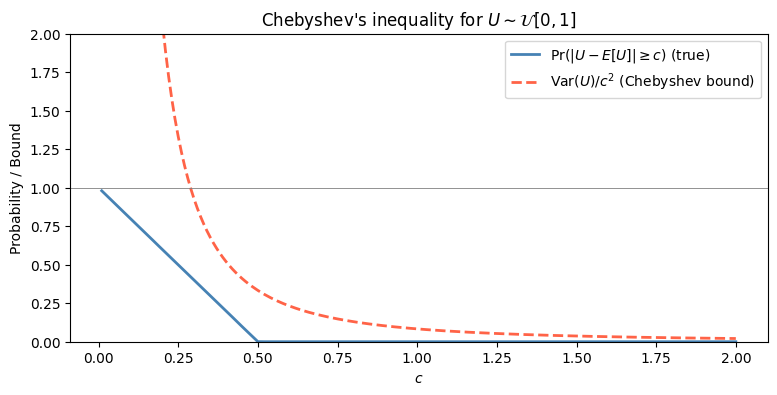

In [12]:
# Plotting True Probability Distribution vs Chebyshev's Inequality Bound

# Store all possible values of variable a
c_values = np.linspace(0.01, 2, 200)

# Evaluate true probability i.e P(∣U−E[U]∣≥c)
true_probability = [np.mean(np.abs(uniform_dist - expectation_u) >= c) for c in c_values]

# Evaluate Chebyshev's Bound using formula Var(U)/c^2
chebyshev_bound = variance_u / (c_values**2)

plt.figure(figsize=(9, 4))
plt.plot(c_values, true_probability, label=r"$\Pr(|U - E[U]| \geq c)$ (true)",  color="steelblue", lw=2)
plt.plot(c_values, chebyshev_bound,  label=r"$\mathrm{Var}(U)/c^2$ (Chebyshev bound)", color="tomato", lw=2, linestyle="--")
plt.ylim(0, 2)
plt.axhline(1, color="gray", lw=0.6)
plt.xlabel("$c$")
plt.ylabel("Probability / Bound")
plt.title("Chebyshev's inequality for $U \\sim \\mathcal{U}[0, 1]$")
plt.legend()
plt.show()

(c) Compare & Interpret

Both graphs(Markov's & Chebyshev's) compare the true probability of a Uniform Distribution $U ← [0, 1]$ to the relevant 'worst-case' or upper bounds on the probability that a random variable $a$ deviates from its mean.

### Markov's Graph
Markov's inequality provides an upper bound on the probability that a non-negative random variable is greater than or equal to some positive constant $a$. It relies only on the expected value (the mean). 

First, the true probability (blue line) decreases linearly because $U$ is uniformly distributed. The Markov bound (dashed red) follows a hyperbolic curve.

Another obvious observation is that the dashed orange line is always above the solid blue line, which visually proves Markov's rule: the actual probability never exceeds the bound. However, at the point where $a < 0.5$. The orange curve shoots above the horizontal gray line at y = 1. A probability bound greater than 1 (or 100%) is mathematically true, but practically useless. Markov's bound only starts becoming somewhat informative as $a$ gets closer to 1, but it remains a very "loose" (inaccurate) estimation for this specific uniform distribution.


### Chebyshev's Graph
Chebyshev's inequality bounds the probability that a random variable deviates from its mean by more than a certain distance, $c$. It requires knowing both the mean and the variance, hence is a step up to Markov's inequality.

Because Chebyshev relies on $c^2$ in the denominator, the dashed hyperbolic curve drops much faster and more aggressively than the Markov curve. It provides a much "tighter" bound for the tails of the distribution.  Because we are using the variance ($\sigma^2 \approx 0.0833$), the Chebyshev bound (dashed red) is significantly tighter than the Markov bound at higher values of $c$. The true probability (blue line) hits zero exactly at $c = 0.5$ because no value in $\mathcal{U}[0, 1]$ can be further than 0.5 from the mean. Chebyshev's curve approaches this zero-point much faster than Markov's curve does. However, just like Markov, for very small distances from the mean (where $c$ is tiny), the bound shoots well above probability >= 1.0, making it uninformative in that specific range.

---

(ii) Consider a normally distributed real number with mean 0 and variance 1, i.e. X ← N(0, 1).

    
(a) Plot $prob(X ≥ a)$ and $\frac{E[X]}{a}$ as functions of a

In [13]:
np.random.seed(42)

# No of iterations to run
N = 300_000
normal_dist = np.random.normal(0, 1, N)

expectation_x = np.mean(normal_dist)
variance_x = np.var(normal_dist)

print(f"E[X] = {expectation_x}")
print(f"Var[X] = {variance_x}")

E[X] = 0.00014652298559371263
Var[X] = 0.9997903994502505


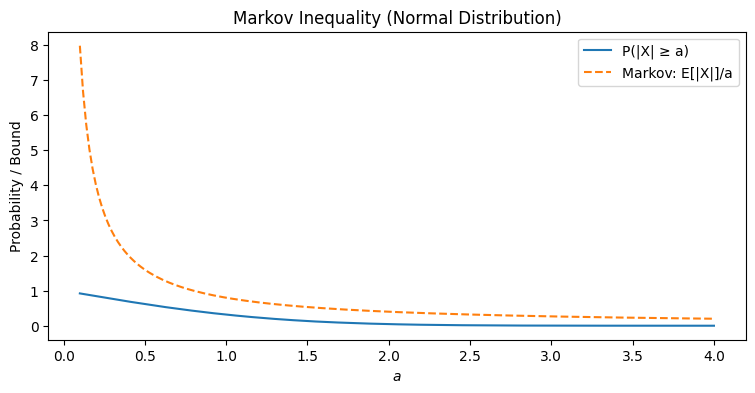

In [14]:
a_values = np.linspace(0.1, 4, 200)

# Markov's Inequality deals w/ non-negative values, use absolute values of X i.e |X|
absoluteX = np.abs(normal_dist)
expectation_absX = np.mean(absoluteX)
plt.figure(figsize=(9, 4))

true_probability = [np.mean(absoluteX >= a) for a in a_values]
markov_bound = expectation_absX / a_values

plt.plot(a_values, true_probability, label="P(|X| ≥ a)")
plt.plot(a_values, markov_bound, '--', label="Markov: E[|X|]/a")

plt.title("Markov Inequality (Normal Distribution)")
plt.xlabel("$a$")
plt.ylabel("Probability / Bound")
plt.legend()
plt.show()



(b) Plot $prob(|X − EX| ≥ c)$ and $\frac{varX}{c^2}$ as functions of c.

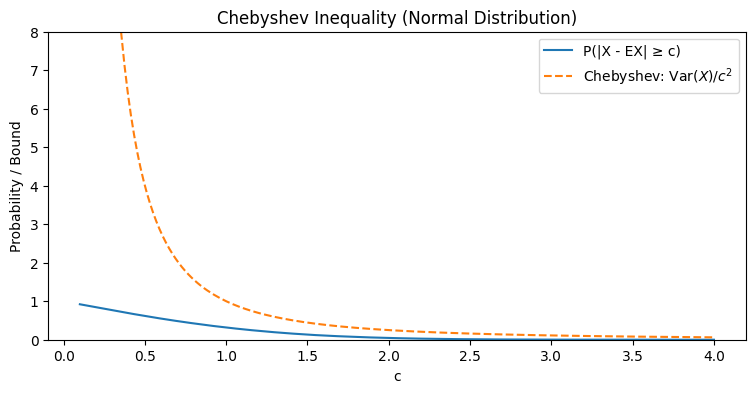

In [15]:
c_vals = np.linspace(0.1, 4, 200)

# Evaluate true probability distribution
true_prob = [np.mean(np.abs(normal_dist - expectation_x) >= c) for c in c_vals]
# Evaluate Chebyshev bound
chebyshev_bound = variance_x / (c_vals**2)

# Plot 
plt.figure(figsize=(9, 4))

plt.plot(c_vals, true_prob, label="P(|X - EX| ≥ c)")
plt.plot(c_vals, chebyshev_bound, '--', label=r"Chebyshev: $\mathrm{Var}(X)/c^2$")

plt.title("Chebyshev Inequality (Normal Distribution)")
plt.xlabel("c")
plt.ylim(0, 8)
plt.ylabel("Probability / Bound")
plt.legend()
plt.show()

    
(c) Compare and interpret.

### Markov’s Inequality (Normal Distribution)

Markov’s inequality is applied here to the absolute value $|X|$ to ensure non-negativity.

The dashed curve represents $\frac{\mathbb{E}[|X|]}{a}$. the bound follows the curve $0.798/a$.  the true probability drops very quickly because the Normal distribution's "tails" are thin; most of the data is concentrated near the mean. Similar to the uniform case, the Markov bound is trivial (above 1.0) for small values of $a$. It remains a very loose upper limit because Markov's inequality is "distribution-agnostic"—it doesn't know the data is Normal, so it must account for much "heavier" possible tails.  

For the Normal distribution, the Chebyshev bound is a much more powerful tool. Because the Normal distribution has a defined variance, Chebyshev can provide a tighter "ceiling" on how often extreme values (outliers) occur compared to the simpler Markov bound.

### Chebyshev’s Inequality (Normal Distribution)

This graph measures how likely it is for a sample to land $c$ units away from the mean. The tail in the Chebyshev graph drops much more rapidly compared to Markov's bound because Chebyshev uses the variance, it captures the "spread" of the Normal distribution. It can be observed that the dashed curve in the Chebyshev plot stays closer to the true probability than the Markov bound does as $c$ increases

(iii) Consider a fair die, i.e. D ← {1, 2, 3, 4, 5, 6} with uniform distribution.

(a) Plot $prob(D ≥ a)$ and $\frac{ED}{a}$ as functions of a


In [16]:
np.random.seed(42)

N = 300_000
die = np.random.randint(1, 7, N)

expectation_die = np.mean(die)
variance_die = np.var(die)

print(f"E[D] = {expectation_die}")
print(f"Var[D] = {variance_die}")

E[D] = 3.50078
Var[D] = 2.9147993916


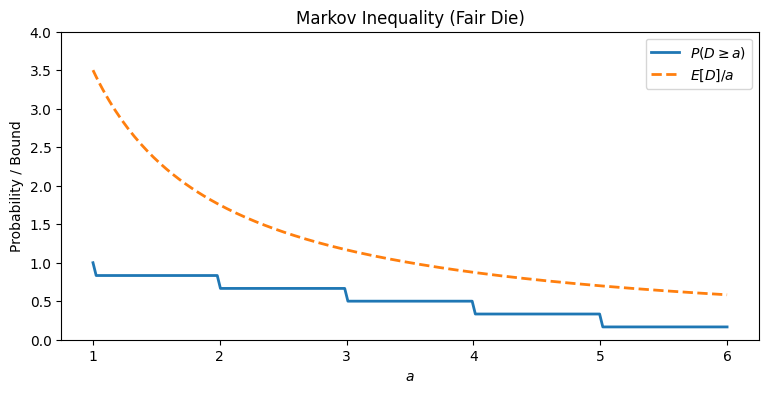

In [17]:
a_values = np.linspace(1, 6, 200)

true_probab = [np.mean(die >= a) for a in a_values]
markov_bound = expectation_die / a_values

plt.figure(figsize=(9, 4))

plt.plot(a_values, true_probab, label=r"$P(D \geq a)$", lw=2)

plt.plot(a_values, markov_bound, '--', label=r"$E[D]/a$", lw=2)

plt.xlabel("$a$")
plt.ylabel("Probability / Bound")
plt.title("Markov Inequality (Fair Die)")
plt.ylim(0, 4)
plt.legend()
plt.show()

(b) Plot $prob(|D − ED| ≥ c)$ and $\frac{varD}{c2}$ as functions of c

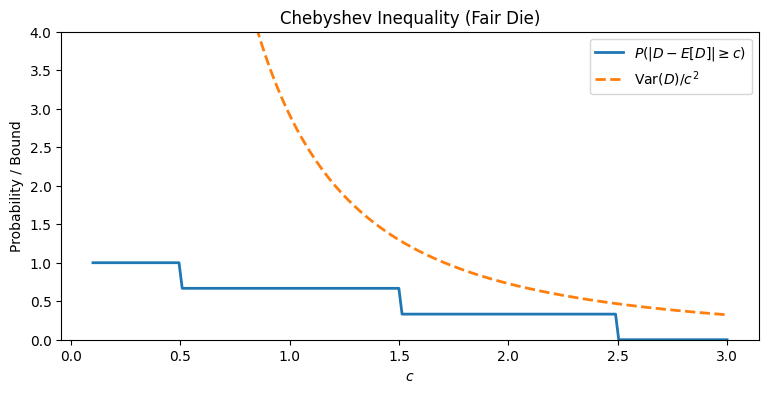

In [18]:
c_values = np.linspace(0.1, 3, 200)

true_pr =[np.mean(np.abs(die - expectation_die) >= c) for c in c_values]
chebyshev_bound = variance_die / (c_values**2)

plt.figure(figsize=(9, 4))

plt.plot(c_values, true_pr, label=r"$P(|D - E[D]| \geq c)$", lw=2)

plt.plot(c_values, chebyshev_bound, '--', label=r"$\mathrm{Var}(D)/c^2$", lw=2)

plt.xlabel("$c$")
plt.ylabel("Probability / Bound")
plt.title("Chebyshev Inequality (Fair Die)")
plt.ylim(0, 4)
plt.legend()
plt.show()


(c) Compare and interpret.

### Markov’s Inequality (Fair Die)

In this graph, we apply Markov’s inequality to a single fair die, where the expected value $\mathbb{E}[D]$ is 3.5. The blue line represents the actual probability $P(D \ge a)$. Unlike the continuous distributions, this line moves in "steps" because a die is a discrete random variable; the probability only changes when $a$ crosses an integer value from 1 to 6.

Just as with the Normal and Uniform distributions, the Markov bound is trivial (staying well above 1.0) for much of the range where $a$ is small. Because Markov only considers the mean, it provides a very loose "ceiling." For a fair die, the bound remains quite far from the true probability, especially as $a$ approaches 6.

### Chebyshev’s Inequality (Fair Die)

This graph measures the probability that the die roll deviates from the mean of 3.5 by at least $c$ units. For a fair die, the variance $\text{Var}(D)$ is approximately 2.915. The dashed curve follows $\frac{2.917}{c^2}$. Similar to your previous observations, the tail in the Chebyshev graph drops much more rapidly compared to Markov's bound because it incorporates the variance (the "spread") of the die's outcomes.

It can be observed that the dashed curve in the Chebyshev plot stays closer to the true probability than the Markov bound does as $c$ increases. While still a conservative estimate, Chebyshev provides a significantly tighter and more informative "ceiling" for the die's behavior by accounting for how the outcomes are distributed around the average.

